# 01 – Analyse exploratoire : SCANIA Component X

**Objectif :** comprendre les données avant de modéliser, vérifier leur qualité et valider les choix de construction des échantillons et des variables.

Ce notebook s'appuie sur le paquet `cockpit` : les calculs sont dans `src/cockpit/eda.py`, ici on les lance et on commente. Prérequis : avoir exécuté la chaîne de la phase 1 (`make features` ou les modules `cockpit.ingest.*` puis `cockpit.features.pipeline`).

In [1]:
import json
import polars as pl
from IPython.display import Image, display
from cockpit import eda
from cockpit.config import PROJECT_ROOT

stats = eda.run()          # recalcule toutes les figures et statistiques
fig = lambda key: display(Image(filename=str(PROJECT_ROOT / stats["figures"][key]), width=900))

## 1. Vue d'ensemble

In [2]:
pl.DataFrame([{"jeu": k, **v} for k, v in stats["overview"].items()])

jeu,vehicles,readouts,readouts_per_vehicle_median,readouts_per_vehicle_p10,readouts_per_vehicle_p90
str,i64,i64,f64,f64,f64
"""train""",23550,1122452,43.0,15.0,83.0
"""validation""",5046,196227,34.0,11.0,73.0
"""test""",5045,198140,34.0,11.0,74.0


In [3]:
stats["events"]

{'repairs': 2272,
 'censored': 21278,
 'repair_rate': 0.09647558386411889,
 'study_length_repaired_median': 208.39999389648438,
 'study_length_censored_median': 219.0,
 'study_length_max': 510.0}

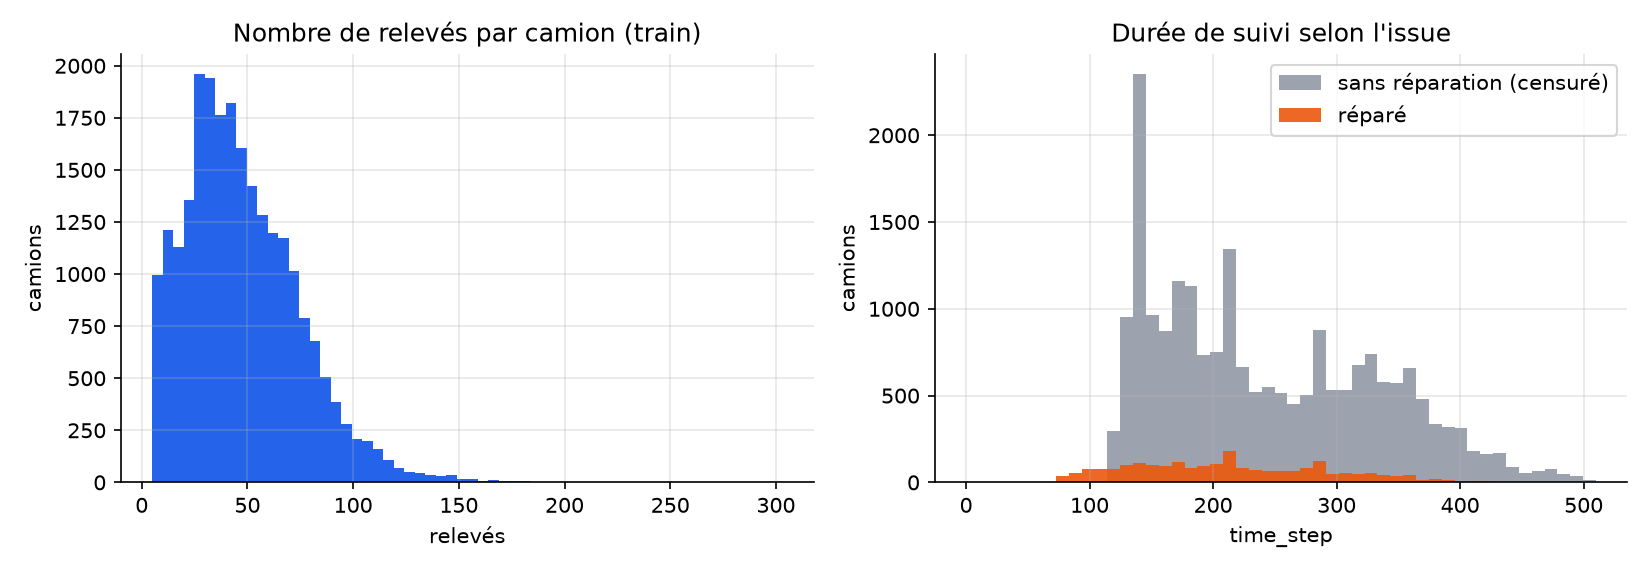

In [4]:
fig("overview")

**Lecture.**
- 23 550 camions d'entraînement et environ 5 000 en validation et en test ; 43 relevés par camion en médiane à l'entraînement, 34 en validation et en test (historiques coupés).
- **9,6 % des camions** ont eu une réparation du composant X pendant l'étude. Les camions réparés ont un suivi plus court, puisque l'étude s'arrête à la réparation.
- Aucun camion censuré n'est suivi moins d'environ 115 pas de temps : les camions non réparés ont tous un historique assez long.

## 2. Survie de la flotte

{'S(100)': 0.9942675159235667, 'S(200)': 0.9468815316991284, 'S(300)': 0.8659351364339172, 'S(400)': 0.7901005316049486, 'S(500)': 0.7207266904076791}
Spécification la plus discriminante : Spec_2


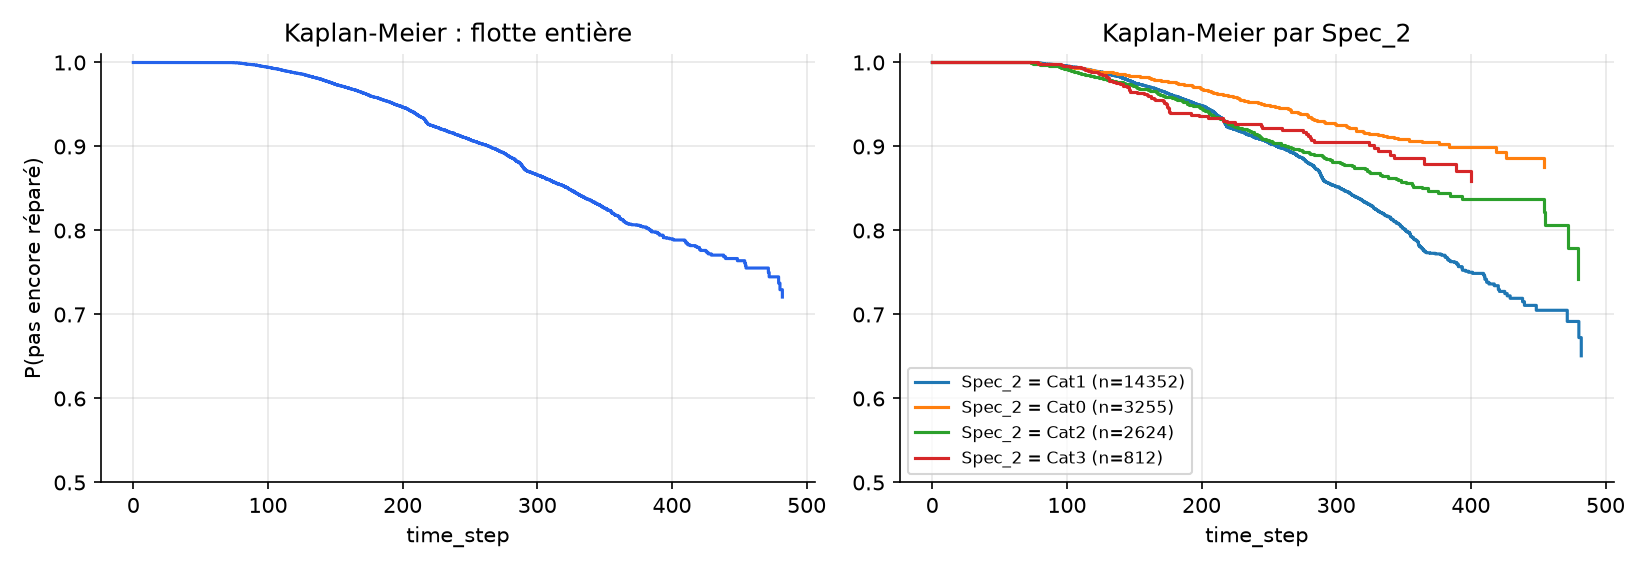

In [5]:
print(stats["km"]); print("Spécification la plus discriminante :", stats["specs"]["most_discriminant"])
fig("survival")

**Lecture.**
- Il n'y a quasiment aucune réparation avant 75 pas de temps, puis le risque augmente régulièrement : environ 5 % des camions sont réparés avant 200 pas de temps, 21 % avant 400 (Kaplan-Meier, qui tient compte des camions censurés).
- La pente s'accentue avec l'âge : le risque instantané augmente, ce qui est cohérent avec une usure.
- Les spécifications séparent nettement des segments : selon la catégorie de `Spec_2`, le taux de réparation varie du simple au triple. Elles seront utiles au modèle et à la segmentation de la flotte dans le tableau de bord.

## 3. Régularité des relevés

{'median': 4.4000244140625, 'p90': 7.600006103515625, 'p99': 26.400001525878906, 'share_gap_1': 0.0248393396317415, 'first_readout_median': 5.199999809265137}


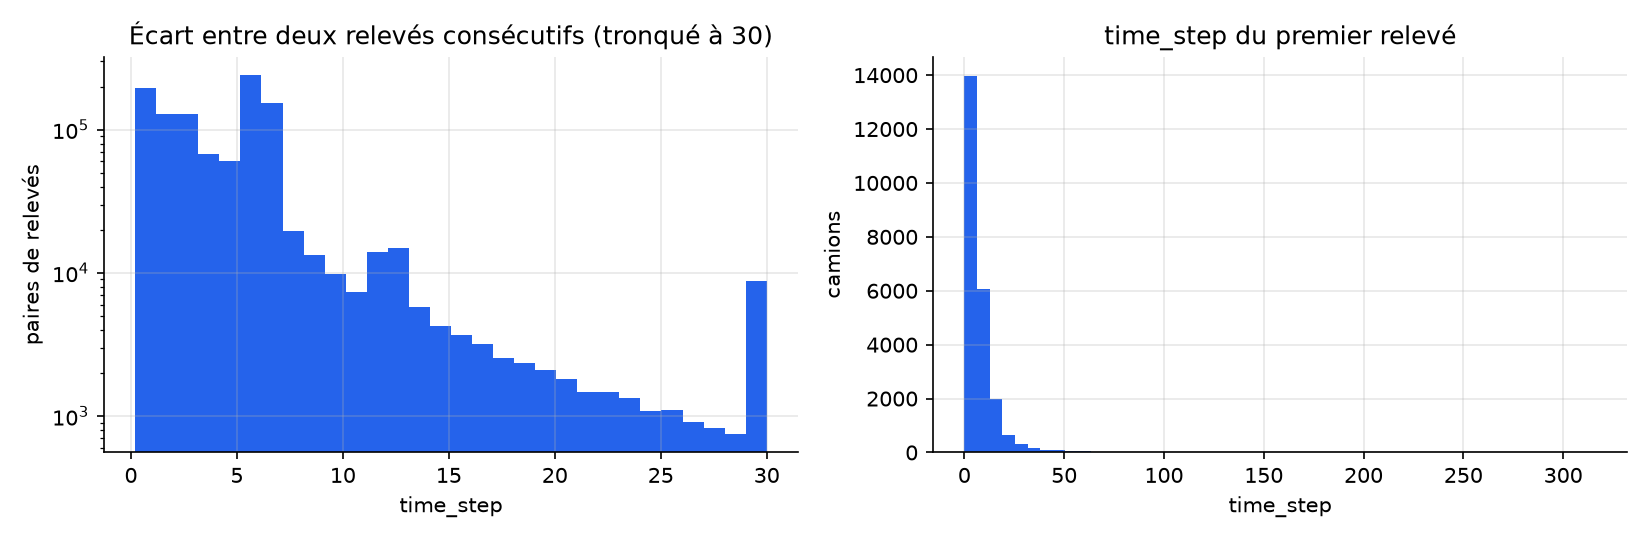

In [6]:
print(stats["gaps"]); fig("gaps")

**Lecture.** Les relevés sont **irréguliers** : écart médian de 4,4 pas de temps, mais 10 % des écarts dépassent 7,6 et quelques-uns dépassent 30. Le premier relevé arrive tôt (médiane 5,2). D'où le choix de variables exprimées **par unité de temps** (rythmes) plutôt que par relevé, et de variables qui décrivent la régularité du suivi (écart moyen, dernier écart).

## 4. Qualité des données

In [7]:
pl.DataFrame([{"jeu": k, "relevés": v["rows"], "relevés avec manquant": v["rows_with_missing"],
               "camions concernés": v["vehicles_with_missing"], "camions": v["vehicles"]}
              for k, v in stats["quality"].items()])

jeu,relevés,relevés avec manquant,camions concernés,camions
str,i64,i64,i64,i64
"""train""",1122452,22481,6988,23550
"""validation""",196227,3937,1300,5046
"""test""",198140,4164,1346,5045


In [8]:
{k: (v["counter_decreases"], v["histogram_bin_decreases"], v["histogram_missing_rows"])
 for k, v in stats["quality"].items()}

{'train': ({'171_0': 7,
   '666_0': 0,
   '427_0': 0,
   '837_0': 0,
   '309_0': 0,
   '835_0': 0,
   '370_0': 0,
   '100_0': 0},
  {'167': 0, '272': 0, '291': 0, '158': 0, '459': 0, '397': 0},
  {'167': 2862, '272': 525, '291': 9628, '158': 648, '459': 8353, '397': 610}),
 'validation': ({'171_0': 0,
   '666_0': 0,
   '427_0': 0,
   '837_0': 0,
   '309_0': 0,
   '835_0': 0,
   '370_0': 0,
   '100_0': 0},
  {'167': 0, '272': 0, '291': 0, '158': 0, '459': 0, '397': 0},
  {'167': 496, '272': 92, '291': 1585, '158': 128, '459': 1397, '397': 110}),
 'test': ({'171_0': 0,
   '666_0': 0,
   '427_0': 0,
   '837_0': 0,
   '309_0': 0,
   '835_0': 0,
   '370_0': 0,
   '100_0': 0},
  {'167': 0, '272': 0, '291': 0, '158': 0, '459': 0, '397': 0},
  {'167': 874, '272': 99, '291': 1774, '158': 122, '459': 1435, '397': 115})}

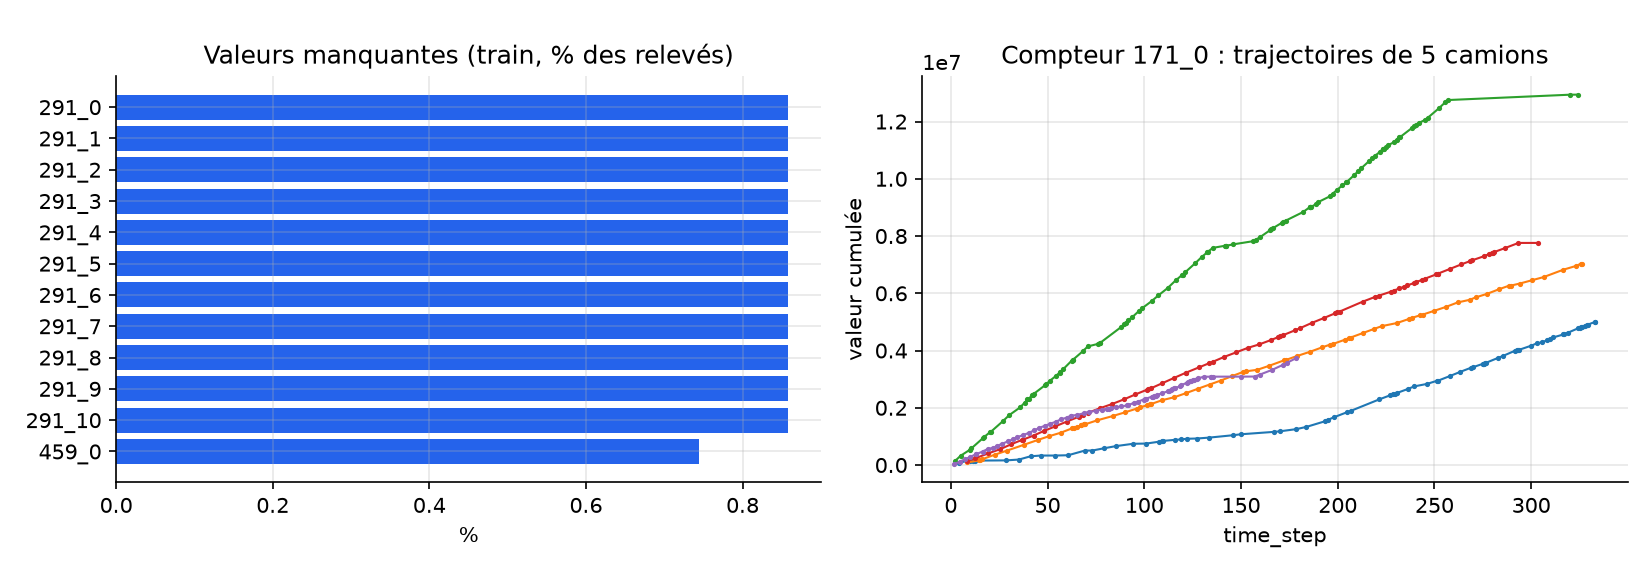

In [9]:
fig("quality")

**Lecture.**
- Moins de 1 % des valeurs manquent et ce sont des **blocs entiers** : quand un histogramme manque, ses 10 à 36 classes manquent ensemble (surtout les histogrammes 291 et 459). On les complète par la dernière valeur connue du camion, ce qui n'utilise que le passé.
- Les compteurs et les histogrammes sont bien **cumulatifs** : aucune classe d'histogramme ne décroît d'un relevé au suivant, et seulement 7 décroissances sur 1,1 million de transitions pour le compteur 171. Quelques valeurs redescendent toutefois après une période manquante (voir le rapport qualité) : les accroissements récents correspondants sont marqués manquants.
- Les trajectoires de compteurs sont presque linéaires dans le temps, avec des pentes différentes d'un camion à l'autre : c'est la **pente** (intensité d'utilisation) qui porte l'information, pas le niveau.

## 5. Tirage des instants de coupure : un piège évité

En validation et en test, l'historique de chaque camion est coupé à un instant choisi par SCANIA. Pour l'entraînement, on doit tirer nous-mêmes ces instants. Le premier essai, un tirage **uniforme** parmi les relevés, a révélé un problème.

In [10]:
pl.DataFrame([{"tirage": k, "âge médian": v["median_age"], "AUC de l'âge": v["auc_age"], "positifs": v["positives"],
               **{f"âge méd. classe {c}": a for c, a in v["median_age_by_class"].items()}}
              for k, v in stats["cutoff_age"].items()])

tirage,âge médian,AUC de l'âge,positifs,âge méd. classe 0,âge méd. classe 1,âge méd. classe 2,âge méd. classe 3,âge méd. classe 4
str,f64,f64,i64,f64,f64,f64,f64,f64
"""uniforme""",112.800003,0.695245,3391,89.199997,130.800003,147.899994,154.199997,161.600006
"""calé sur la validation""",135.800003,0.563405,5092,121.599998,130.800003,137.399994,138.700012,144.399994
"""validation officielle""",169.399994,0.43037,136,170.0,153.100006,203.199997,126.0,160.799988


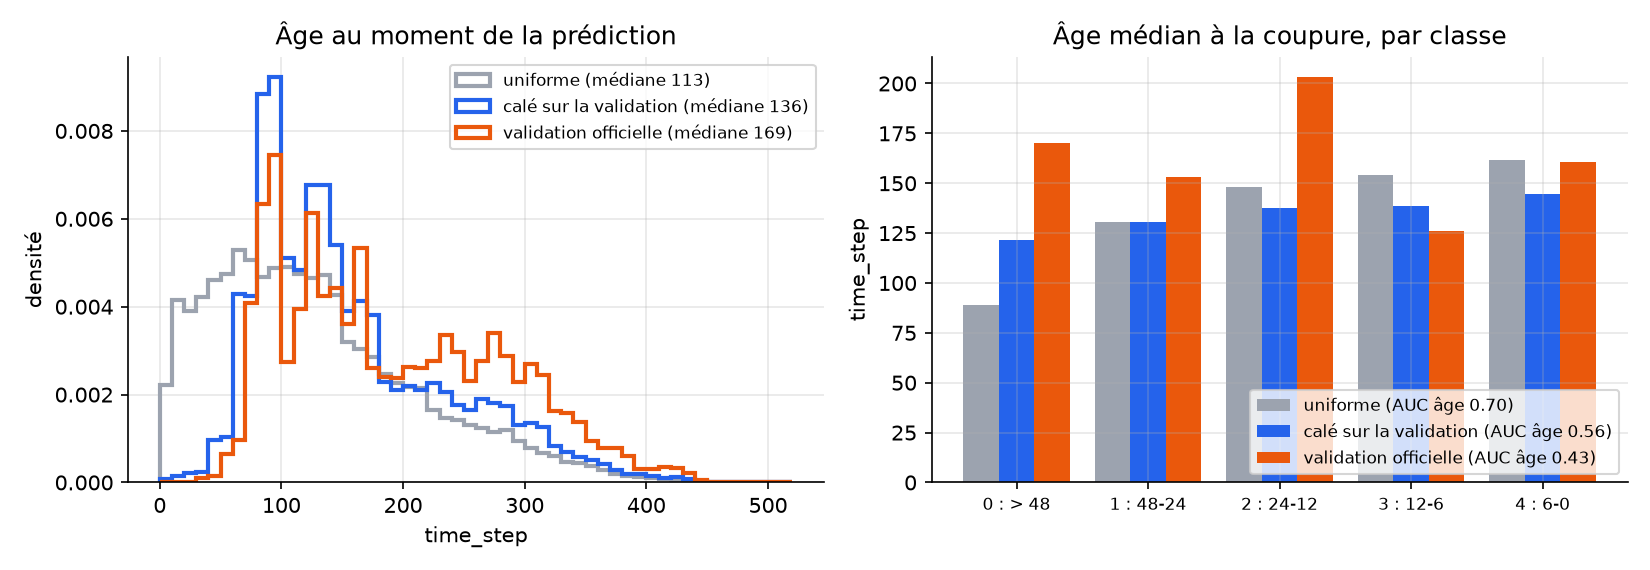

In [11]:
fig("sampling")

**Lecture.**
- Avec le tirage uniforme, les coupures sont trop jeunes (âge médian 113 contre 169 en validation), et surtout la classe 0 est beaucoup plus jeune que les classes de panne (89 contre 162). L'âge seul prédit alors la panne avec une AUC de **0,70**, alors qu'en validation son AUC est de **0,43** : le modèle apprendrait un **raccourci qui n'existe pas** dans les conditions d'évaluation.
- On tire donc les coupures avec des poids qui calent leur âge sur celui de la validation (rapport de densités par tranches de 20 pas de temps). L'AUC de l'âge tombe à 0,56 et on obtient 1,5 fois plus d'exemples positifs.
- Le calage n'est pas parfait (âge médian 136), car un camion ne peut pas être coupé après la fin de son suivi. Le reste de l'écart sera traité en phase 2 par pondération des échantillons. Seuls les **âges** de la validation sont utilisés, jamais ses classes, et le jeu de test n'est pas touché.

## 6. Les cibles

Échantillons d'entraînement : {'train_cutoffs': 117592, 'train_vehicles': 23550, 'unknown_label': 37779, 'class_counts_train_cutoffs': {'None': 37779, '0': 74721, '1': 2280, '2': 1250, '3': 668, '4': 894}, 'positive_rate_known': 0.0637991304674677, 'n_features': 193}
Validation / test : {'validation': {'0': 4910, '1': 16, '2': 14, '3': 30, '4': 76}, 'test': {'0': 4903, '1': 26, '2': 15, '3': 41, '4': 60}}


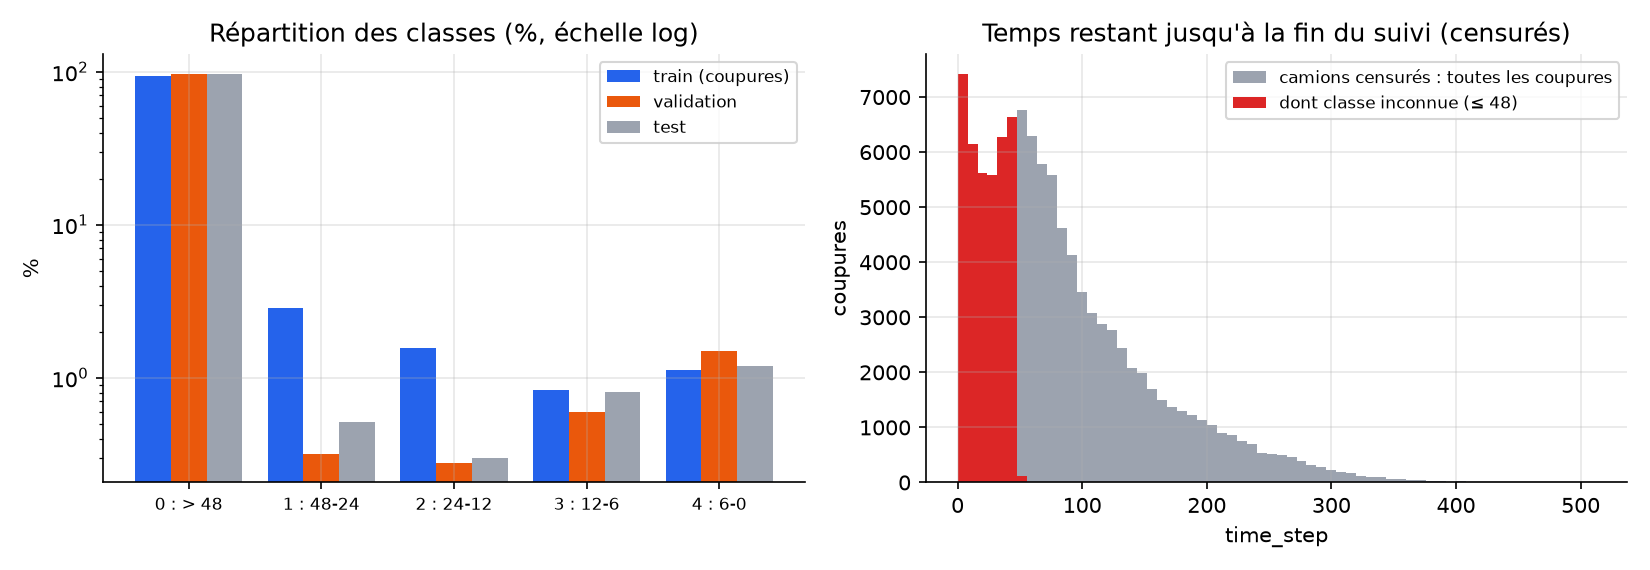

In [12]:
print("Échantillons d'entraînement :", stats["samples"]); print("Validation / test :", stats["labels"])
fig("labels")

**Lecture.**
- Classes très déséquilibrées : 2,7 % de camions en phase de panne en validation, 2,8 % en test.
- La **répartition entre classes de panne diffère** : en validation, la classe 4 (panne dans moins de 6 pas de temps) représente 56 % des positifs, contre 18 % dans nos échantillons d'entraînement. SCANIA a donc sur-représenté les instants proches de la panne. En phase 2, il faudra **corriger les probabilités a priori** avant d'appliquer la décision au coût minimal, sinon les coûts seront mal estimés.
- Les coupures de camions censurés situées à moins de 48 pas de temps de la fin du suivi ont une classe **inconnue** (en rouge) : on ne sait pas si une panne est survenue juste après l'étude. Elles servent aux modèles de survie, pas aux classifieurs.

## 7. Pouvoir discriminant des variables

In [13]:
pl.DataFrame(stats["top_features"]).head(20)

feature,auc,strength,missing
str,f64,f64,f64
"""cnt_666_last""",0.677235,0.177235,0.0
"""cnt_666_rate_all""",0.65992,0.15992,0.0
"""cnt_837_last""",0.65975,0.15975,0.0
"""hist_459_total_rate_all""",0.659114,0.159114,0.009522
"""cnt_309_last""",0.651436,0.151436,0.0
…,…,…,…
"""cnt_427_rate_all""",0.633049,0.133049,0.00525
"""hist_272_total_rate_recent""",0.632303,0.132303,0.0
"""hist_397_total_rate_recent""",0.632271,0.132271,0.0


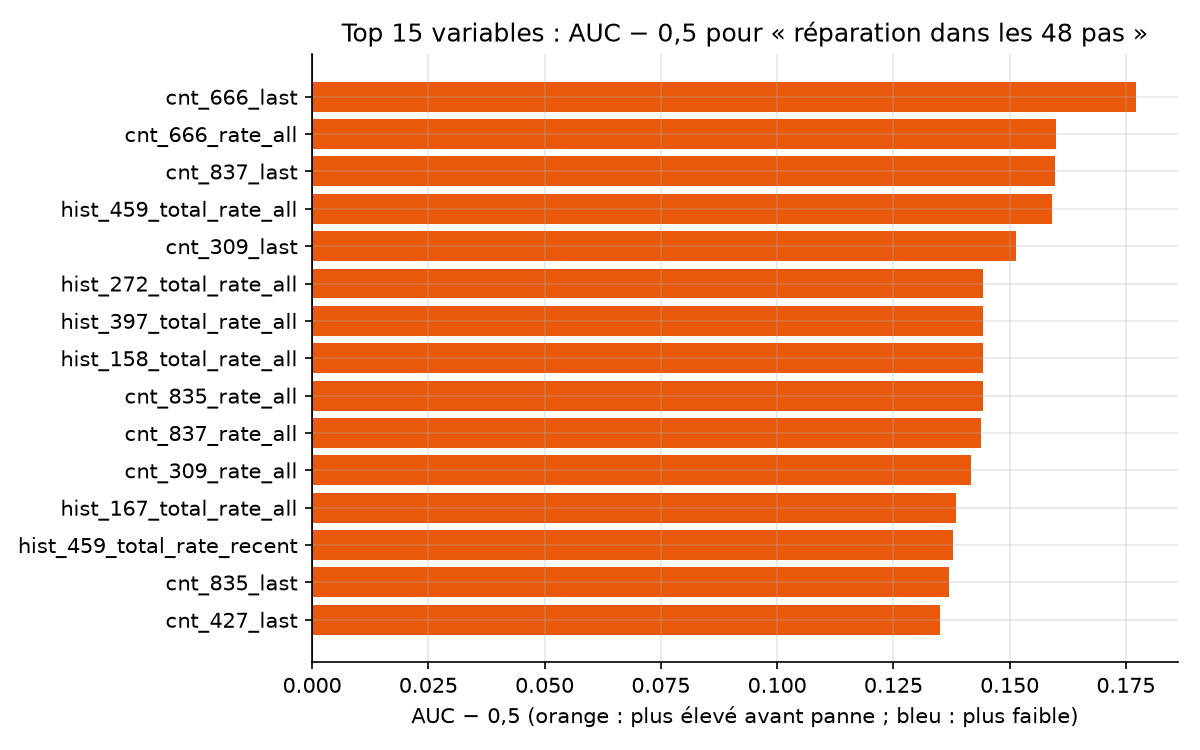

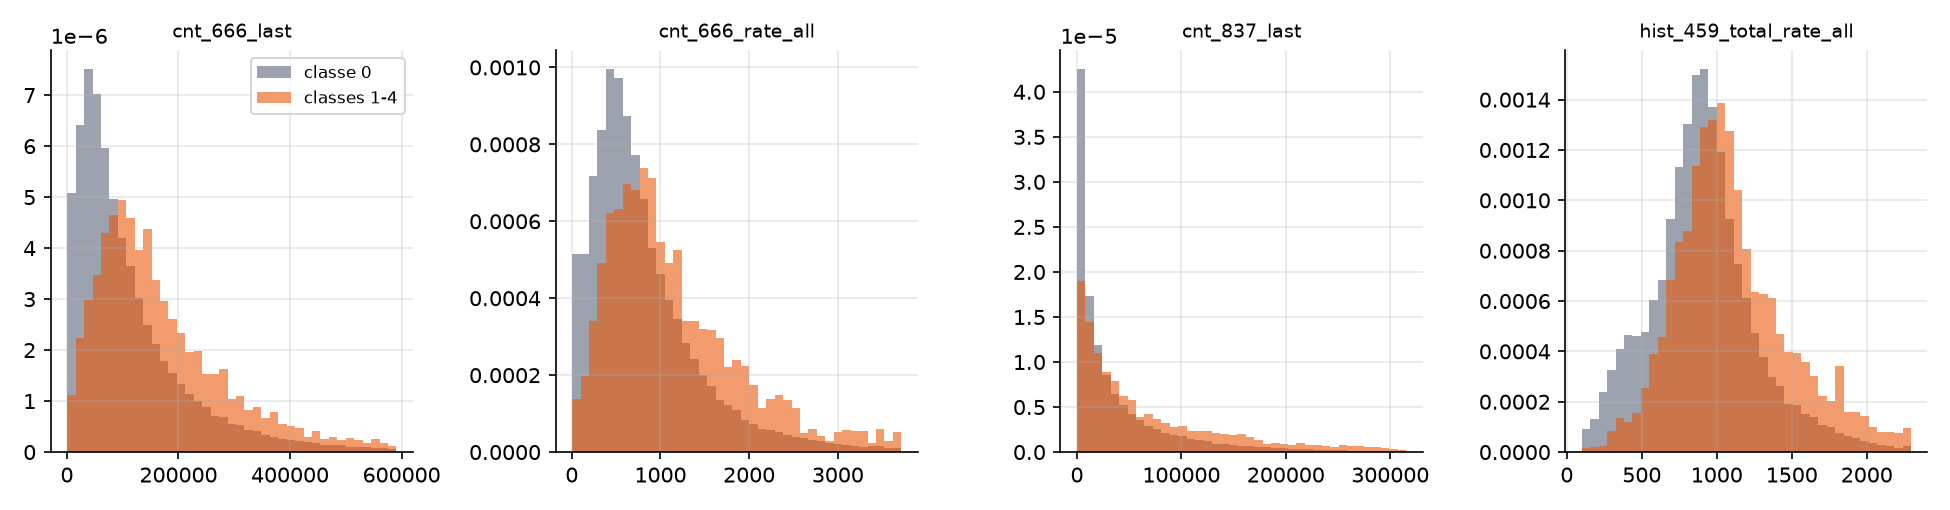

In [14]:
fig("signal"); fig("top_dists")

**Lecture.**
- Les variables les plus discriminantes sont des **intensités d'utilisation** : rythme moyen des compteurs (`cnt_*_rate_all`), vitesse de remplissage des histogrammes (`hist_*_total_rate_all`), et dernières valeurs des compteurs. Un camion très utilisé tombe plus souvent en panne.
- Les AUC individuelles plafonnent autour de 0,65-0,68 : aucune variable ne suffit seule, il faudra les combiner.
- Plusieurs variables mesurent la même chose (les vitesses de remplissage de plusieurs histogrammes ont exactement la même AUC : elles comptent probablement le même temps de fonctionnement). Voir la redondance ci-dessous.

Corrélation maximale entre rythmes de compteurs : 0.964


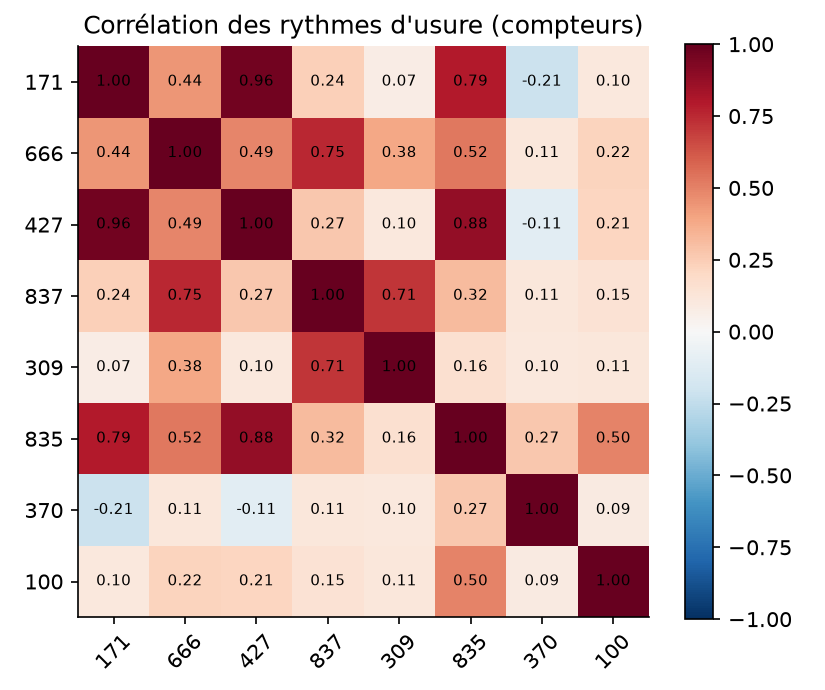

In [15]:
print("Corrélation maximale entre rythmes de compteurs :", round(stats["counter_rate_corr_max_offdiag"], 3)); fig("corr")

## 8. Profils d'utilisation

{'167': 0.04874323836520489, '272': 0.04922672884251256, '291': 0.02038745116442442, '158': 0.0274064214900136, '459': 0.04481078643584624, '397': 0.033822496747234254}


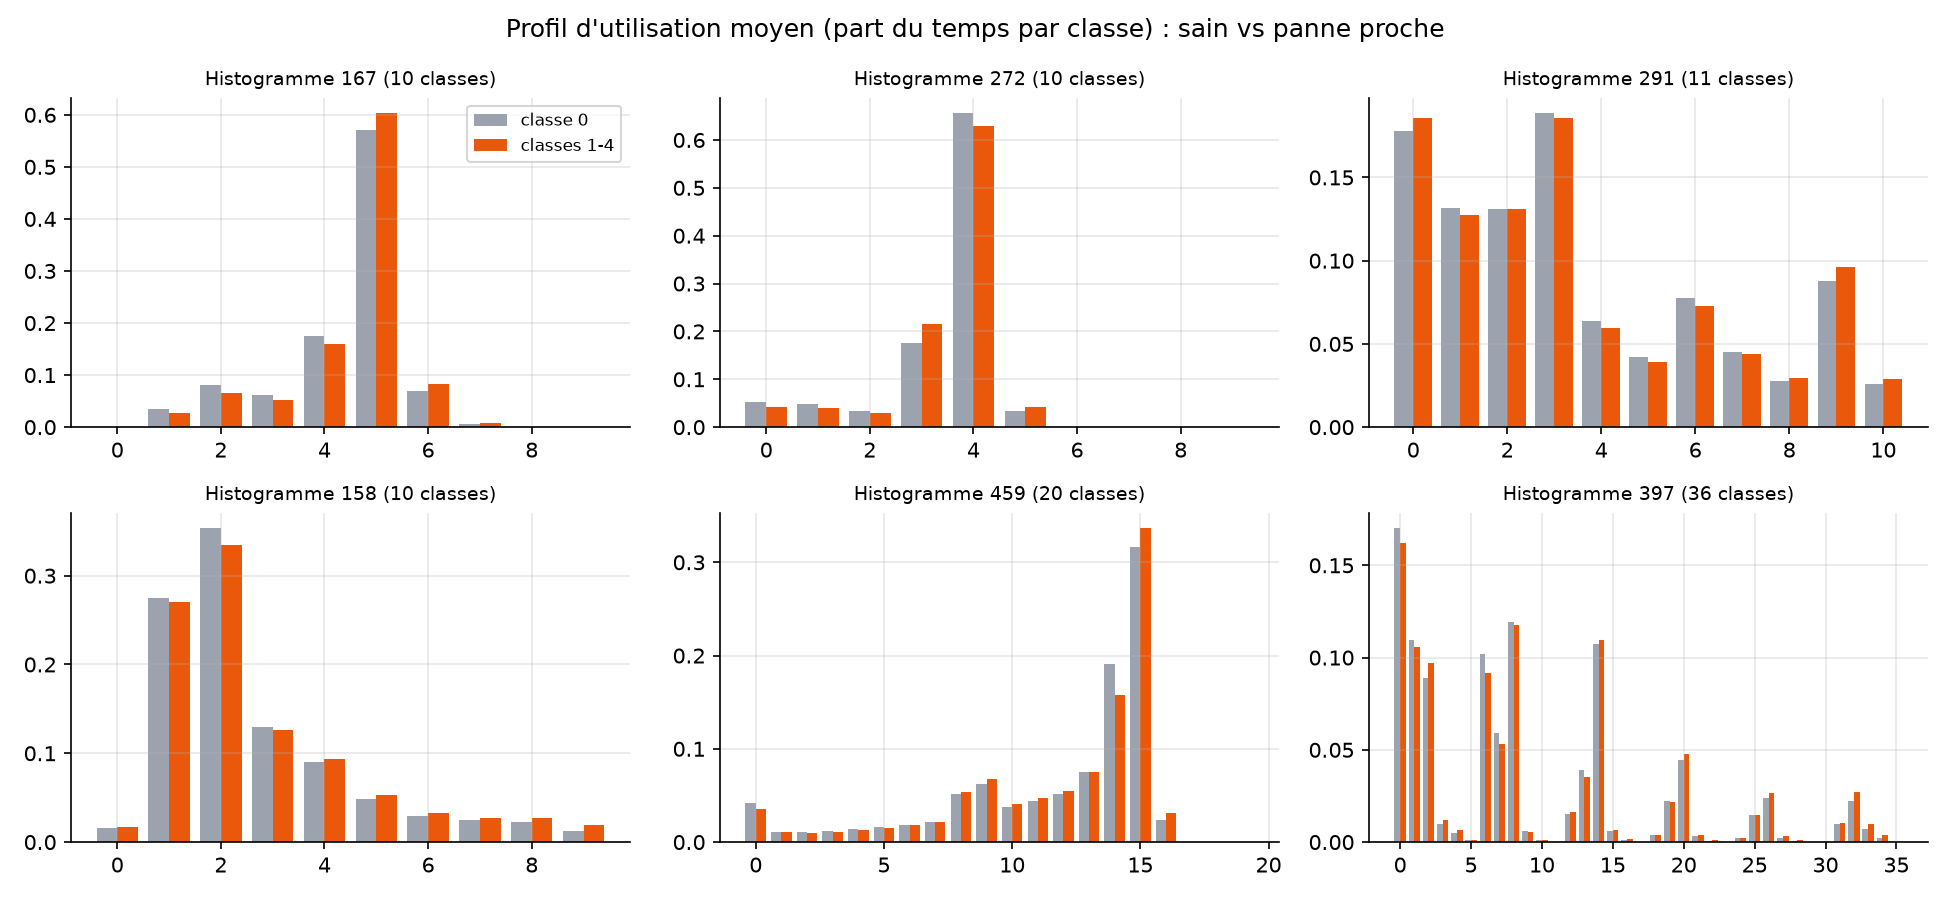

In [16]:
print(stats["histogram_profile_tv_distance"]); fig("profiles")

**Lecture.** Les profils moyens des camions proches de la panne diffèrent peu de ceux des camions sains (distance de variation totale de 2 à 5 %), mais de façon cohérente : plus de temps dans les classes hautes de 167, 459 et 158, c'est-à-dire un usage plus intense. Le signal est faible pour chaque classe prise seule, mais il est réparti sur beaucoup de variables : un modèle à base d'arbres, qui combine des variables faibles, est adapté.

## 9. Conclusions pour la phase 2

1. **Échantillonnage** : garder le tirage calé sur l'âge de la validation et compléter par une pondération des échantillons.
2. **Probabilités a priori** : corriger l'écart de répartition des classes (sur-représentation de la classe 4 en évaluation) avant la décision au coût minimal.
3. **Variables** : les intensités d'utilisation dominent. Il faut supprimer les doublons (vitesses de remplissage identiques) pour les modèles linéaires comme Cox, mais on peut tout garder pour les arbres.
4. **Validation** : plis groupés par camion. Avec seulement 136 positifs en validation et 142 en test, il faut toujours donner des intervalles de confiance.
5. **Censure** : garder les échantillons à classe inconnue pour les modèles de survie, qui savent les utiliser.